    Time  Laser_Power
0      1   100.496714
1      2    99.861736
2      3   100.647689
3      4   101.523030
4      5    99.765847
5      6    99.765863
6      7   101.579213
7      8   100.767435
8      9    99.530526
9     10   100.542560
10    11    99.536582
11    12    99.534270
12    13   100.241962
13    14    98.086720
14    15    98.275082
15    16    99.437712
16    17    98.987169
17    18   100.314247
18    19    99.091976
19    20    98.587696
20    21   101.465649
21    22    99.774224
22    23   100.067528
23    24    98.575252
24    25    99.455617
25    26   100.110923
26    27    98.849006
27    28   100.375698
28    29    99.399361
29    30    99.708306
Mean: 99.81185310414892
Standard Deviation: 0.9000064274024115
UCL: 102.51187238635616
CL: 99.81185310414892
LCL: 97.11183382194169
Empty DataFrame
Columns: [Time, Laser_Power]
Index: []


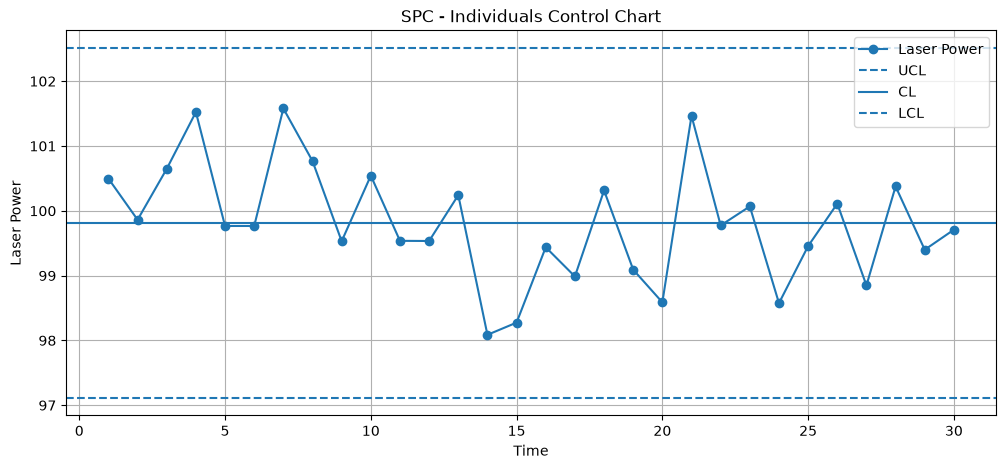

In [8]:
#正常波动的模拟
#SPC 基础（Statistical Process Control 统计过程控制）
#第一步：导入Python库

import numpy as np #创建模拟数据和数学计算
import pandas as pd #数据整理与统计分析
import matplotlib.pyplot as plt #绘制 SPC 控制图

#第二步：创建模拟设备数据
np.random.seed(42) #设置随机数种子。

#作用：生成 30 个符合正态分布（Normal Distribution，即钟形曲线）的随机数，代表激光功率。
laser_power = np.random.normal(
    loc=100, #loc=100：均值（Mean）为 100。意味着这 30 个数据的中心值在 100 左右。
    scale=1, #scale=1：标准差（Standard Deviation）为 1。意味着大部分数据会落在 100 ± 1（即 99 到 101）的区间内。
    size=30  ##size=30：生成 30 个数据点（想象成连续采集了 30 片晶圆的激光功率）。
)
#结果：laser_power 现在是一个包含 30 个浮点数的 NumPy 数组。

df = pd.DataFrame({
    "Time": range(1, 31),
    "Laser_Power": laser_power
})

print(df)

#第三步：计算 Mean 和 Standard Deviation
mean_value = df["Laser_Power"].mean()

std_value = df["Laser_Power"].std()

print("Mean:", mean_value)

print("Standard Deviation:", std_value)

#第四步：计算 UCL、CL、LCL
UCL = mean_value + 3 * std_value

CL = mean_value

LCL = mean_value - 3 * std_value

print("UCL:", UCL)
print("CL:", CL)
print("LCL:", LCL)

#第五步：识别超出控制限的数据
out_of_control = df[
    (df["Laser_Power"] > UCL) |
    (df["Laser_Power"] < LCL)
]

print(out_of_control)

#第六步：绘制 Individuals Control Chart
plt.figure(figsize=(12, 5)) #创建画布。创建一个空白的画布（Figure）,准备开始画图。figsize=(12,5)设定画布的尺寸，12是宽度，5是高度（单位是英寸）。

#绘制数据折线图。把刚才生成的 30 个数据点画到图上，并用线连起来。
plt.plot(
    df["Time"],        #X 轴的数据（第 1 到 30 片）
    df["Laser_Power"], #Y 轴的数据（激光功率的真实值）
    marker="o",        #给每个数据点画一个小圆圈（o 代表 circle）
    label="Laser Power" #给这条线起个名字，后面用来生成图例（Legend）
)             

#绘制控制线（三条水平线）。axhline 代表 "Axis Horizontal Line"（水平轴线），用来画横跨整个图表的参考线。
plt.axhline(UCL, linestyle="--", label="UCL") #UCL（Upper Control Limit，控制上限）：linestyle="--" 画成虚线

plt.axhline(CL, linestyle="-", label="CL") #CL（Center Line，中心线，通常是均值）：linestyle="-" 画成实线

plt.axhline(LCL, linestyle="--", label="LCL") #LCL（Lower Control Limit，控制下限）：linestyle="--" 画成虚线

#设置坐标轴标签。给 X 轴和 Y 轴加上文字说明
plt.xlabel("Time")

plt.ylabel("Laser Power")

#设置图表标题
plt.title("SPC - Individuals Control Chart")

#显示图例
plt.legend()

#显示网格
plt.grid(True)

#展示图表
plt.show()

In [ ]:
#实际工作中，不需要随机生成数据，而是读一个文件
import pandas as pd
import matplotlib.pyplot as plt

# 实际工作中：不再用 np.random 生成，而是直接读取真实记录
# 假设从机台导出了 CSV 文件
df = pd.read_csv("laser_tool_data.csv")

# 或者从数据库读取
# df = pd.read_sql("SELECT Time, Laser_Power FROM table", connection)

print(df.head()) # 查看真实数据

    Time  Laser_Power
25    26   105.110923
26    27   103.849006
27    28   105.375698
28    29   104.399361
29    30   104.708306


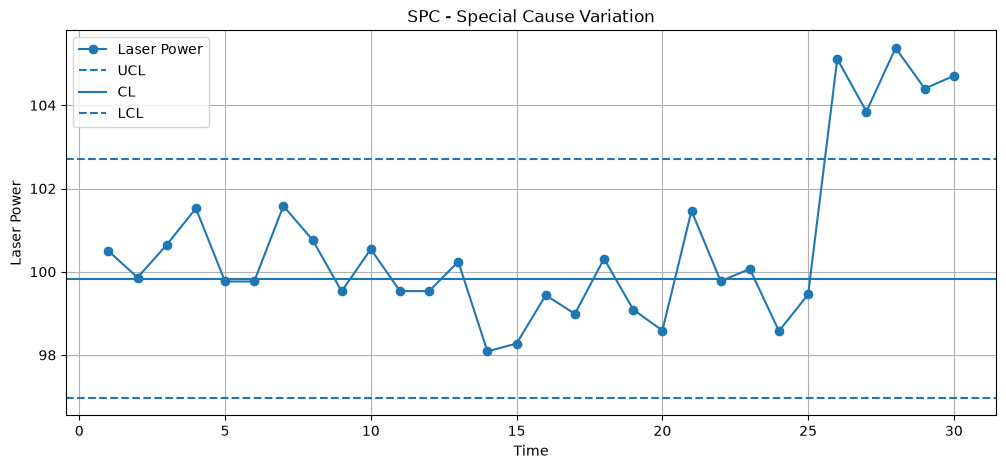

In [9]:
#异常波动的模拟
#第一步：导入Python库

import numpy as np #创建模拟数据和数学计算
import pandas as pd #数据整理与统计分析
import matplotlib.pyplot as plt #绘制 SPC 控制图

#第二步：创建模拟设备数据
np.random.seed(42)

#生成“正常”数据（25个点）
normal_data = np.random.normal(100, 1, 25)

#生成“异常”数据（5个点）
abnormal_data = np.random.normal(105, 1, 5)

#拼接数据：laser_power 现在是一个长度为 30 的一维数组，前 25 个值在 100 附近，后 5 个值在 105 附近。
laser_power = np.concatenate([
    normal_data,
    abnormal_data
])

#构建数据表
df = pd.DataFrame({
    "Time": range(1, 31),
    "Laser_Power": laser_power
})

#第三步：计算
#提取基线数据（Baseline）
baseline = df["Laser_Power"].iloc[:25] #从 df 表格中，提取 Laser_Power（激光功率）这一列的前 25 个数据。

#计算均值（Center Line 的基础）
mean_value = baseline.mean()

#计算标准差（衡量波动大小）
std_value = baseline.std()

#计算控制限（3σ 原则）
UCL = mean_value + 3 * std_value

CL = mean_value

LCL = mean_value - 3 * std_value

#第四步：筛选异常数据
out_of_control = df[
    (df["Laser_Power"] > UCL) |
    (df["Laser_Power"] < LCL)
]

print(out_of_control)

#绘制异常控制图

plt.figure(figsize=(12, 5))

plt.plot(
    df["Time"],
    df["Laser_Power"],
    marker="o",
    label="Laser Power"
)

plt.axhline(UCL, linestyle="--", label="UCL")

plt.axhline(CL, linestyle="-", label="CL")

plt.axhline(LCL, linestyle="--", label="LCL")

plt.xlabel("Time")

plt.ylabel("Laser Power")

plt.title("SPC - Special Cause Variation")

plt.legend()

plt.grid(True)

plt.show()

            M1          M2          M3          M4          M5
0   100.496714   99.861736  100.647689  101.523030   99.765847
1    99.765863  101.579213  100.767435   99.530526  100.542560
2    99.536582   99.534270  100.241962   98.086720   98.275082
3    99.437712   98.987169  100.314247   99.091976   98.587696
4   101.465649   99.774224  100.067528   98.575252   99.455617
5   100.110923   98.849006  100.375698   99.399361   99.708306
6    99.398293  101.852278   99.986503   98.942289  100.822545
7    98.779156  100.208864   98.040330   98.671814  100.196861
8   100.738467  100.171368   99.884352   99.698896   98.521478
9    99.280156   99.539361  101.057122  100.343618   98.236960
10  100.324084   99.614918   99.323078  100.611676  101.031000
11  100.931280   99.160782   99.690788  100.331263  100.975545
12   99.520826   99.814341   98.893665   98.803793  100.812526
13  101.356240   99.927990  101.003533  100.361636   99.354880
14  100.361396  101.538037   99.964174  101.564644   97

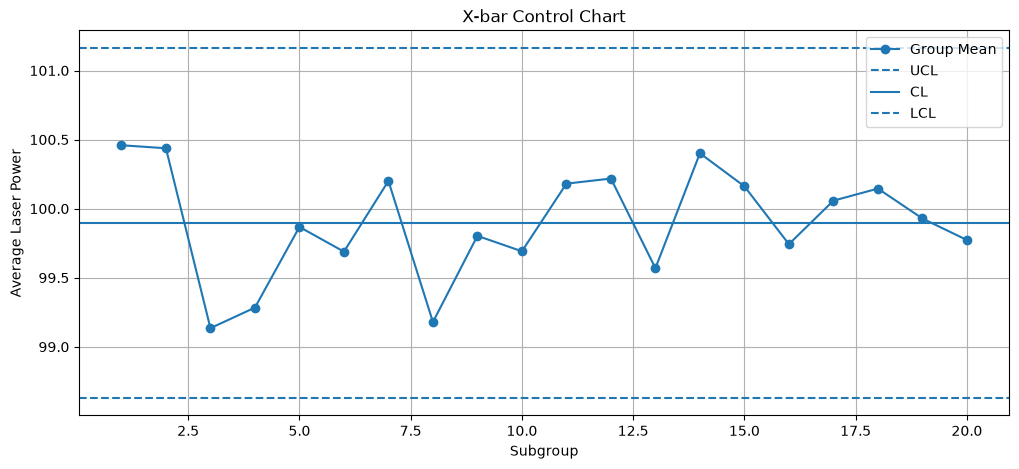

In [13]:
#X-bar Chart 的 Python 实践
#创建Subgroup数据
#第一步：导入Python库

import numpy as np #创建模拟数据和数学计算
import pandas as pd #数据整理与统计分析
import matplotlib.pyplot as plt #绘制 SPC 控制图

#第二步：创建模拟设备数据
np.random.seed(42)

#生成二维正态分布数据
data = np.random.normal(
    loc=100,      #所有数据的均值都是100
    scale=1,      #标准差为1
    size=(20, 5)  #生成一个符合正态分布的二维矩阵（Matrix）20行X5列
)

#转换为 Pandas DataFrame
df = pd.DataFrame(
    data,         #传入刚才生成的 20×5 的数据矩阵
    columns=["M1", "M2", "M3", "M4", "M5"] #给这 5 列分别命名为 M1、M2、M3、M4、M5
)

print(df)

#计算每组的 Mean:df["Group_Mean"] = ...的意思是把刚刚算出来的 20 个平均值，作为新的一列存入表格最右侧。
df["Group_Mean"] = df[
    ["M1", "M2", "M3", "M4", "M5"] #从原表中把这 5 列单独“抽”出来。注意这里用了双层中括号，这表示你要选择多列（返回一个包含 5 列的子 DataFrame）。如果是单列，只需要一层中括号 df["M1"]
].mean(axis=1) #。mean()是求平均值的函数;axis=1代表"按行计算".
#在 Pandas 中，axis=0 代表“按列计算”（比如算出 M1 这一列 20 天的平均值）；
#而 axis=1 代表“按行计算”（即跨越行方向，把第一行的 M1+M2+M3+M4+M5 加起来除以 5）。

print(df["Group_Mean"])

#计算每组的 Range
#把 M1 到 M5 这 5 列单独抽出来，存到一个叫 measurements（测量值）的变量里。
#这就好比把这一块区域单独框起来，方便后续操作。
measurements = df[
    ["M1", "M2", "M3", "M4", "M5"]
]

#计算极差（Range）
#找出每一行（每个时间点）的最大值，减去最小值，把结果作为新列 Range（极差）存入表格
df["Range"] = (
    measurements.max(axis=1) -      #measurements.max(axis=1)：横向（跨列）找出每行的最大值
    measurements.min(axis=1)        #measurements.min(axis=1)：横向（跨列）找出每行的最小值
)

#只把刚才算出来的“均值列”和“极差列”打印出来看看。注意这里用了双层中括号，代表选取多列输出。
print(df[["Group_Mean", "Range"]])

#计算 X-bar Chart 控制限
X_double_bar = df["Group_Mean"].mean() #(总均值 / 中心线)把 20 行数据的 Group_Mean 再求一次平均

R_bar = df["Range"].mean() #平均极差）：把 20 行数据的 Range 求平均。代表了设备在正常状态下的平均波动幅度。

A2 = 0.577 #统计学常数

UCL = X_double_bar + A2 * R_bar

CL = X_double_bar

LCL = X_double_bar - A2 * R_bar

print("UCL:", UCL)

print("CL:", CL)

print("LCL:", LCL)

#绘制 X-bar Chart
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, 21),      #X 轴：range(1, 21)，即第 1 组到第 20 组（子组）。
    df["Group_Mean"],  #Y 轴：df["Group_Mean"]，也就是刚才算出来的每一组的平均值。
    marker="o",
    label="Group Mean"
)

plt.axhline(UCL, linestyle="--", label="UCL")

plt.axhline(CL, linestyle="-", label="CL")

plt.axhline(LCL, linestyle="--", label="LCL")

plt.xlabel("Subgroup")

plt.ylabel("Average Laser Power")

plt.title("X-bar Control Chart")

plt.legend()

plt.grid(True)

plt.show()